# 04 Competitor benchmark

Is Bangladesh gaining or losing ground in US and EU apparel imports? This notebook compares Bangladesh with eight other suppliers: China, Vietnam, India, Cambodia, Pakistan, Türkiye, Indonesia and Sri Lanka.

Data: US imports by partner from UN Comtrade (US-reported), and EU27 imports from outside the EU from Eurostat Comext, both HS 61+62, monthly from 2010. EU values are converted from EUR at the ECB monthly rate. Only full calendar years are used for annual shares. Run `src/download_competitors.py` first.

In [1]:
import sys
sys.path.insert(0, '../src')
import pandas as pd
import competitors as C
from explore_utils import TAB, ROOT

d = C.load()
a, share = C.annual(d)
print(d.groupby('market').date.agg(['min', 'max']))
share.round(1).tail(6)

              min        max
market                      
EU     2010-01-01 2026-08-01
US     2010-01-01 2026-07-01


partner        BD    CN   ID   IN   KH   LK   PK   TR    VN  WORLD
market year                                                       
US     2020   7.4  27.5  5.2  4.5  4.3  2.2  2.1  1.1  18.5  100.0
       2021   8.3  25.2  5.0  5.1  4.3  2.1  2.8  1.1  17.3  100.0
       2022   9.3  22.4  5.6  5.7  4.4  2.1  2.8  1.1  17.9  100.0
       2023   8.9  21.8  5.3  5.7  4.3  2.1  2.6  1.3  17.7  100.0
       2024   8.8  22.0  5.3  5.9  4.8  2.1  2.8  1.1  18.3  100.0
       2025  10.0  14.6  5.9  6.3  6.2  2.3  3.1  1.2  20.8  100.0

## Market shares over time

Share of each supplier in total imports (all countries for the US, all non-EU countries for the EU).

PosixPath('/Users/taky_tahmid/Library/CloudStorage/GoogleDrive-tahmid@udel.edu/Other computers/My Laptop/UDel/Taky_research/bd_business_analytics/rmg-export-forecasting/outputs/figures/fig_comp02_eu_shares.png')

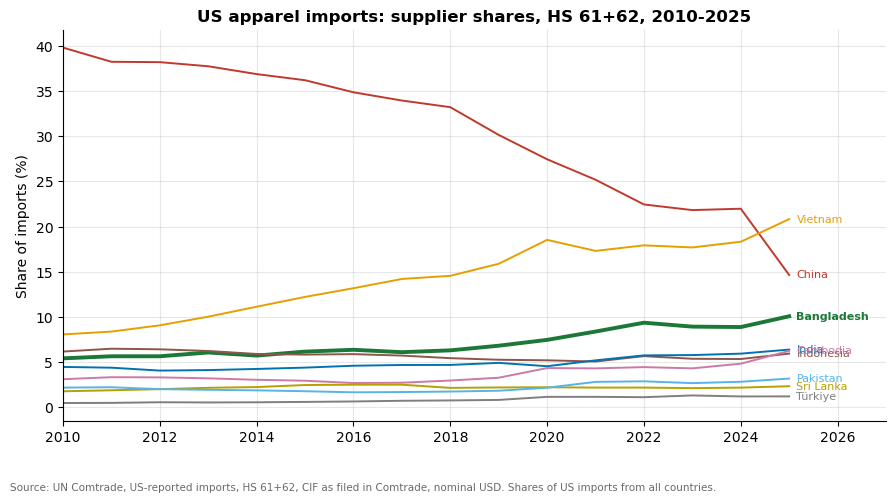

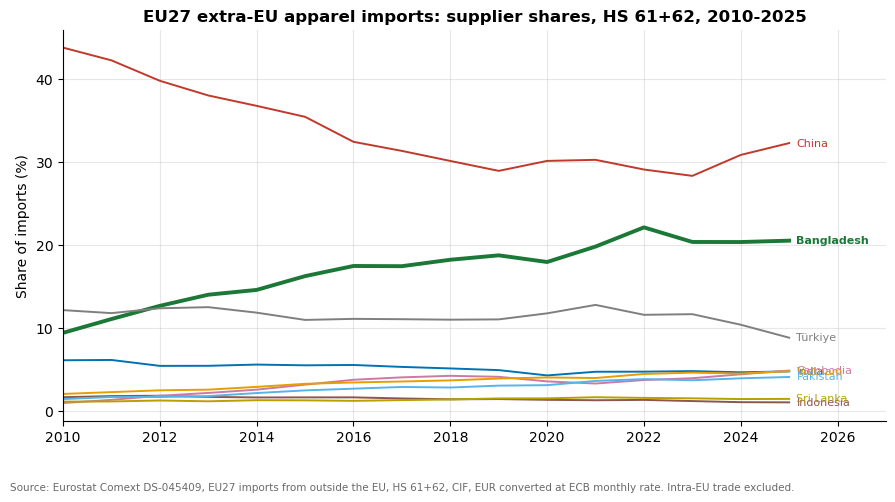

In [2]:
C.plot_shares(share, 'US', 'fig_comp01_us_shares')
C.plot_shares(share, 'EU', 'fig_comp02_eu_shares')

## Share change at four points: 2010, 2019, 2022, 2025

2019 is the last year before COVID. 2022 was the peak year for US apparel imports.

In [3]:
st = C.share_table(share)
st.to_csv(TAB / 'competitor_share_changes.csv', index=False)
st.sort_values(['market', 2025], ascending=[True, False])

year,market,partner,country,2010,2019,2022,2025,chg_2010_2025_pp,chg_2022_2025_pp
1,EU,CN,China,43.74,28.90,29.06,32.24,-11.50,3.18
0,EU,BD,Bangladesh,9.40,18.73,22.10,20.50,11.10,-1.60
7,EU,TR,Türkiye,12.14,11.02,11.57,8.82,-3.32,-2.75
4,EU,KH,Cambodia,0.96,4.11,3.72,4.86,3.90,1.14
8,EU,VN,Vietnam,2.05,3.90,4.45,4.80,2.75,0.35
3,EU,IN,India,6.10,4.92,4.73,4.76,-1.34,0.03
6,EU,PK,Pakistan,1.42,3.05,3.83,4.09,2.67,0.26
5,EU,LK,Sri Lanka,1.12,1.51,1.57,1.45,0.33,-0.12
2,EU,ID,Indonesia,1.65,1.43,1.33,1.03,-0.62,-0.30
17,US,VN,Vietnam,8.03,15.87,17.91,20.82,12.79,2.91


## Ranking in 2025

In [4]:
rk = C.rank_table(a, share, 2025)
rk.to_csv(TAB / 'competitor_rank_2025.csv', index=False)
rk

,market,year,rank,partner,country,value_usd_bn,share_pct
0,US,2025,1,VN,Vietnam,17.020,20.82
1,US,2025,2,CN,China,11.952,14.62
2,US,2025,3,BD,Bangladesh,8.209,10.04
3,US,2025,4,IN,India,5.187,6.35
4,US,2025,5,KH,Cambodia,5.069,6.20
5,US,2025,6,ID,Indonesia,4.823,5.90
6,US,2025,7,PK,Pakistan,2.557,3.13
7,US,2025,8,LK,Sri Lanka,1.862,2.28
8,US,2025,9,TR,Türkiye,0.941,1.15
9,EU,2025,1,CN,China,34.452,32.24


## Decomposing the change from 2022 to 2025

A supplier's imports equal its share times the size of the market. The change splits into two parts that add up exactly:

- market-size effect: the 2022 share applied to the change in total imports
- share effect: the change in share applied to the 2025 market

If the market shrinks, a supplier that holds its share still loses value. The share effect shows whether it did better or worse than the market.

,market,partner,country,y0,y1,value_y0_usd_bn,value_y1_usd_bn,change_usd_bn,market_size_effect_usd_bn,share_effect_usd_bn,market_growth_pct,share_y0_pct,share_y1_pct
0,US,BD,Bangladesh,2022,2025,9.826,8.209,-1.618,-2.201,0.584,-22.402,9.327,10.041
9,EU,BD,Bangladesh,2022,2025,23.003,21.903,-1.100,0.607,-1.707,2.637,22.096,20.499


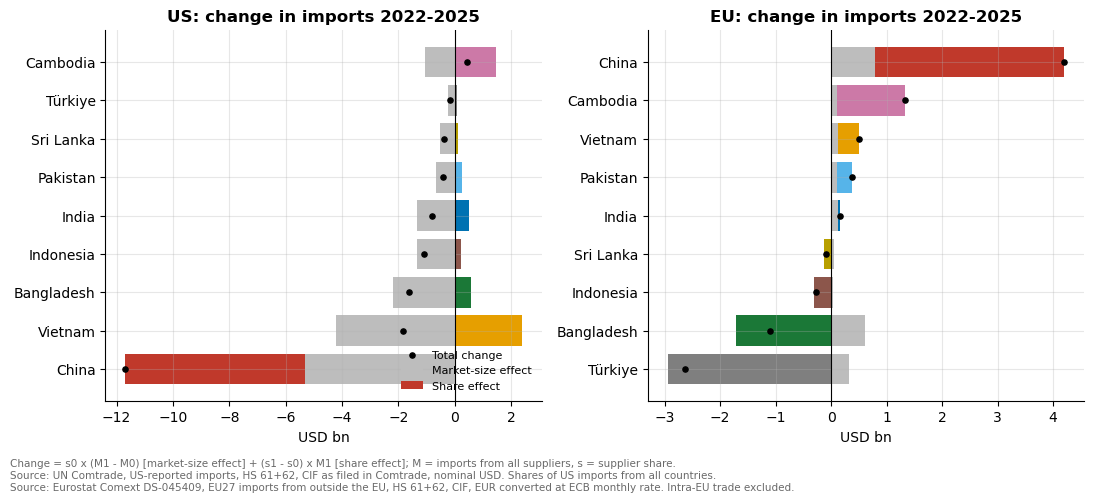

In [5]:
ss = C.shift_share(a)
ss.to_csv(TAB / 'competitor_shift_share_2022_2025.csv', index=False)
C.plot_shift_share(ss, 'fig_comp03_shift_share')
ss[ss.partner == 'BD']

## China+1: who took China's share?

Change in share from 2010 to 2025. Negative bars are losses.

market,EU,US
partner,,
BD,11.09,4.67
CN,-11.49,-25.23
ID,-0.62,-0.23
IN,-1.34,1.93
KH,3.91,3.14
LK,0.33,0.56
PK,2.67,1.00
TR,-3.32,0.73
VN,2.75,12.79


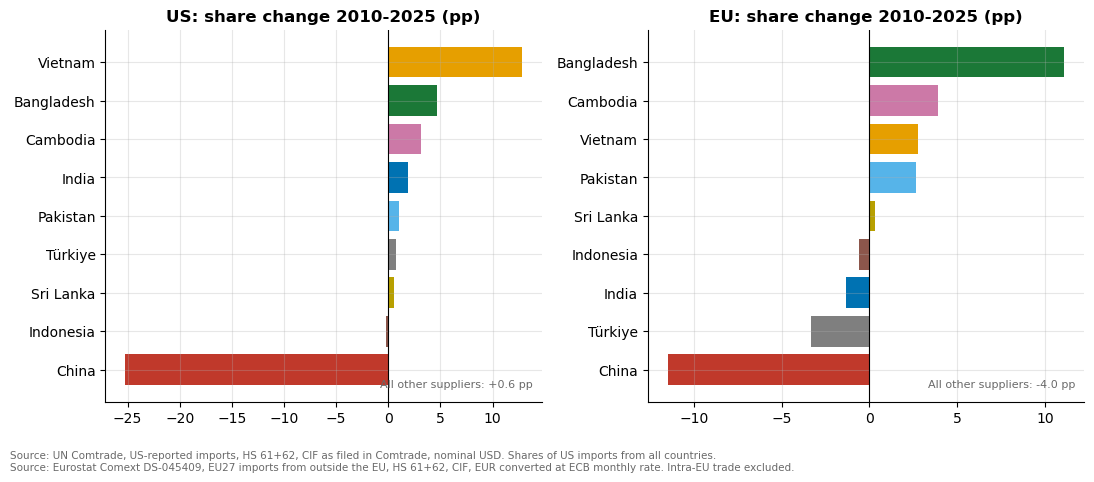

In [6]:
C.plot_china_plus_one(share, 'fig_comp04_china_plus_one')
(share.xs(2025, level='year') - share.xs(2010, level='year')).drop(columns='WORLD').round(2).T

## Power BI tables

In [7]:
pb = ROOT / 'data/processed/powerbi'
iso = {'BD':'BGD','CN':'CHN','VN':'VNM','IN':'IND','KH':'KHM','PK':'PAK','TR':'TUR','ID':'IDN','LK':'LKA','WORLD':'WLD'}
dim = pd.DataFrame([dict(country_key=i+1, partner=p, iso3=iso[p], country=C.NAMES.get(p, 'All suppliers'),
                         is_bangladesh=p == 'BD') for i, p in enumerate(list(C.NAMES) + ['WORLD'])])
dim.to_csv(pb / 'dim_country.csv', index=False)
f = d.merge(dim[['partner', 'country_key']], on='partner')
tot = d[d.partner == 'WORLD'].groupby(['market', 'date']).value_usd.sum().rename('market_total_usd')
f = f.groupby(['date', 'market', 'country_key', 'partner']).value_usd.sum().reset_index().merge(tot.reset_index(), on=['market', 'date'])
f['share_pct'] = (f.value_usd / f.market_total_usd * 100).round(3)
f.to_csv(pb / 'fact_competitors.csv', index=False)
f.tail()

,date,market,country_key,partner,value_usd,market_total_usd,share_pct
3985,2026-08-01,EU,6,PK,3.830324e+08,9.858448e+09,3.885
3986,2026-08-01,EU,7,TR,8.264417e+08,9.858448e+09,8.383
3987,2026-08-01,EU,8,ID,9.553911e+07,9.858448e+09,0.969
3988,2026-08-01,EU,9,LK,1.172740e+08,9.858448e+09,1.190
3989,2026-08-01,EU,10,WORLD,9.858448e+09,9.858448e+09,100.000


## Key facts

In [8]:
bd = st[st.partner == 'BD'].set_index('market')
b = ss[ss.partner == 'BD'].set_index('market')
def first_gainer(m):
    c = (share.loc[m].loc[2025] - share.loc[m].loc[2010]).drop(['WORLD', 'CN'])
    return c.idxmax(), c.max()
facts = []
for m in ['US', 'EU']:
    r = bd.loc[m]
    facts.append(dict(fact=f'Bangladesh share of {m} apparel imports 2010/2019/2022/2025', value=f"{r[2010]:.1f} / {r[2019]:.1f} / {r[2022]:.1f} / {r[2025]:.1f}", unit='%', method='Annual HS 61+62 imports from BD / imports from all suppliers (EU: extra-EU)'))
    rr = b.loc[m]
    facts.append(dict(fact=f'{m}: change in imports from Bangladesh 2022-2025 split', value=f"total {rr.change_usd_bn:+.2f}bn = market size {rr.market_size_effect_usd_bn:+.2f}bn + share {rr.share_effect_usd_bn:+.2f}bn", unit='USD bn', method=f'Shift-share: s0*dM + ds*M1. Market grew {rr.market_growth_pct:+.1f}%'))
    cn = share.loc[m].loc[2025, 'CN'] - share.loc[m].loc[2010, 'CN']
    g, gv = first_gainer(m)
    facts.append(dict(fact=f'{m}: China share change 2010-2025 and biggest gainer', value=f"China {cn:+.1f}pp; {C.NAMES[g]} {gv:+.1f}pp", unit='pp', method='Change in annual share, 2025 minus 2010'))
kf = pd.DataFrame(facts)
kf.to_csv(TAB / 'competitor_key_facts.csv', index=False)
kf

,fact,value,unit,method
0,Bangladesh share of US apparel imports 2010/20...,5.4 / 6.8 / 9.3 / 10.0,%,Annual HS 61+62 imports from BD / imports from...
1,US: change in imports from Bangladesh 2022-202...,total -1.62bn = market size -2.20bn + share +0...,USD bn,Shift-share: s0*dM + ds*M1. Market grew -22.4%
2,US: China share change 2010-2025 and biggest g...,China -25.2pp; Vietnam +12.8pp,pp,"Change in annual share, 2025 minus 2010"
3,Bangladesh share of EU apparel imports 2010/20...,9.4 / 18.7 / 22.1 / 20.5,%,Annual HS 61+62 imports from BD / imports from...
4,EU: change in imports from Bangladesh 2022-202...,total -1.10bn = market size +0.61bn + share -1...,USD bn,Shift-share: s0*dM + ds*M1. Market grew +2.6%
5,EU: China share change 2010-2025 and biggest g...,China -11.5pp; Bangladesh +11.1pp,pp,"Change in annual share, 2025 minus 2010"
